# Research notebook: mathematics and numerics

**Curated source:** [`notebooks/16_mathematical_foundations_replacement.ipynb`](../notebooks/16_mathematical_foundations_replacement.ipynb). The experimental code and outputs below are preserved as committed; no claim of equivalence to other historical notebooks is implied.

This notebook provides the clearest analytical derivation of autonomous persistence and inhibitory termination for ordinary LIF neurons with refreshed self-excitation. It is not the same model as the later sensory-resource autapse.

**Supporting evidence and lineage.** Independent implementation evidence is retained in [11](../notebooks/11_scheduler_independence_audit.ipynb) and especially [12](../notebooks/12_microcircuit_reference_audit.ipynb); [13](../notebooks/13_self_excitation_convergence.ipynb) checks additive-autapse timestep dependence. [14](../notebooks/14_mechanism_comparison.ipynb) and [15](../notebooks/15_replacement_controls.ipynb) established the need for matched old-only controls and multi-spike persistence criteria. The corrected numerical audits matter more than naive spike-count agreement.

See [research/index.md](index.md) for the full 31-notebook map and definition of the benchmark variants. Run from an environment with the source notebook's original dependencies. The code cells below have **not been re-executed as part of the reorganization**.

# ESCM 2.0 — From the neuronal equations to competitive replacement

## Research question

Can the **original assignment-based self-excitation** sustain activity and allow a newly stimulated neuron to suppress a previously active neuron **without** the original persistence gate `P` or custom Brian2 scheduling?

This notebook builds the argument in stages:

1. Derive the **exact subthreshold voltage** for a neuron driven by decaying synaptic currents.
2. Derive a **necessary and sufficient one-spike persistence condition** for a reset neuron with assignment autapse.
3. Derive how a **single inhibitory perturbation** can prevent the next spike, terminating the refresh loop.
4. Extend to **two competing neurons** and test whether a new sensory burst can recruit one while silencing the other.
5. Examine the limits of these conclusions and the next step towards coherent edges.

Every mathematical claim is separated from its numerical test. The single-neuron calculations are evaluated independently of Brian2. The two-neuron experiment uses ordinary Brian2 synapses and no custom scheduling. This is an *isolated two-neuron analysis*, not a proof about the full spatial ESCM.

**Source conventions:** Parameters and input-event timing follow Notebook 15 where applicable: $\tau_m=10$ ms, $\tau_x=3$ ms, $\tau_e=5$ ms, $\tau_i=12$ ms, $v_\mathrm{th}=1$, $W_E=8$, and camera events at 2, 4, 6 ms (old) and 35, 37, 39 ms (new). Notebook 15 has five pixels per edge, a Gaussian spatial inhibition kernel, and additional variants; here those are deliberately reduced to a two-neuron model to make the derivation interpretable.

## 1. Exact membrane response between events

Let $v$ be dimensionless membrane voltage, and $X,E,I$ the external, excitatory and inhibitory currents. Between events,

$$
\tau_m\dot v=-v+X+E-I,\qquad
\tau_x\dot X=-X,\quad\tau_e\dot E=-E,\quad\tau_i\dot I=-I.
$$

At an arbitrary reference time immediately after all events, let $v(0)=v_0$, $X(0)=X_0$, $E(0)=E_0$, and $I(0)=I_0$. Solving by an integrating factor gives

$$
\boxed{v(t)=v_0e^{-t/\tau_m}+X_0K_x(t)+E_0K_e(t)-I_0K_i(t)},
$$

with the **positive voltage-response kernel**

$$
K_j(t)=\frac{\tau_j}{\tau_j-\tau_m}
\left(e^{-t/\tau_j}-e^{-t/\tau_m}\right),\qquad
K_j(t)=\frac{t}{\tau_m}e^{-t/\tau_m}\ \text{when }\tau_j=\tau_m.
$$

These expressions are exact *between spikes*. The neuron emits a spike when $v$ first reaches $v_\mathrm{th}$ **from below**, resets $v\leftarrow0$, and triggers the chosen autaptic update. No continuous response formula by itself determines the next spike; the first threshold crossing must be found. In this notebook all time values are expressed in **milliseconds**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar

# Notebook 15 parameters (ms; currents and voltage dimensionless).
tm, tx, te, ti = 10.0, 3.0, 5.0, 12.0
vth, self_weight, camera_gain = 1.0, 8.0, 6.0

# Exact passive current-to-voltage response; the equal-tau branch is the limit.
def kernel(t, tau):
    t = np.asarray(t, dtype=float)
    if np.isclose(tau, tm):
        return (t / tm) * np.exp(-t / tm)
    return tau / (tau - tm) * (np.exp(-t / tau) - np.exp(-t / tm))

def voltage(t, v0=0.0, X0=0.0, E0=0.0, I0=0.0):
    return (v0*np.exp(-np.asarray(t)/tm) + X0*kernel(t, tx)
            + E0*kernel(t, te) - I0*kernel(t, ti))

# Verify the closed-form impulse kernel against a matrix exponential that
# independently solves the same continuous linear ODE.
from scipy.linalg import expm
M = np.array([[-1/tm, 1/tm, 1/tm, -1/tm],
              [0, -1/tx, 0, 0], [0, 0, -1/te, 0], [0, 0, 0, -1/ti]])
initial = np.array([0.3, 0.8, 2.5, 1.2])
errors = []
for t in np.linspace(0, 50, 201):
    errors.append(abs((expm(M*t) @ initial)[0] - voltage(t, *initial)))
print(f"Independent matrix-exponential check: maximum voltage error = {max(errors):.3g}")
assert max(errors) < 1e-12

Independent matrix-exponential check: maximum voltage error = 6.16e-15


## 2. Exactly when can assignment-based self-excitation sustain firing?

The original ESCM autapse **assigns** $E\leftarrow W_E$ on each output spike. After a spike, assuming no external input, inhibition or adaptation,

$$v(0)=0,\qquad E(0)=W_E,\qquad X(0)=I(0)=0.$$

Until the next spike,

$$\boxed{v(t)=W_EK_e(t).}$$

A subsequent spike exists **if and only if**

$$\boxed{W_E \max_{t\ge0}K_e(t)\ge v_\mathrm{th}.}$$

For $\tau_e\ne\tau_m$, differentiation of $K_e$ yields the peak time

$$t_\mathrm{peak}=\frac{\ln(\tau_m/\tau_e)}{1/\tau_e-1/\tau_m},$$

and the **critical self-excitation strength**

$$\boxed{W_E^{\mathrm{crit}}=\frac{v_\mathrm{th}}{K_e(t_\mathrm{peak})}.}$$

At strict equality the trajectory merely touches threshold. A Brian2 threshold of `v > vth` may therefore *not spike* at equality, especially on a discrete clock. We treat **strictly above** as robust autonomous persistence.

If $W_E>W_E^{\mathrm{crit}}$, the first root of $W_EK_e(t)=v_\mathrm{th}$ gives an interspike interval. After every spike the state is reset to the **same** pair $(v,E)=(0,W_E)$, so the interspike interval repeats exactly in this idealized continuous-time model. This is a genuine one-neuron persistent periodic orbit **without** a special persistence gate. An absolute refractory period would alter the crossing rule and must be analyzed separately.

Peak after a spike: 6.9315 ms; max kernel: 0.2500
Critical assignment weight: W_E > 4.0000 (strict threshold)
For W_E=8: ISI=1.5835 ms, rate=631.5 Hz


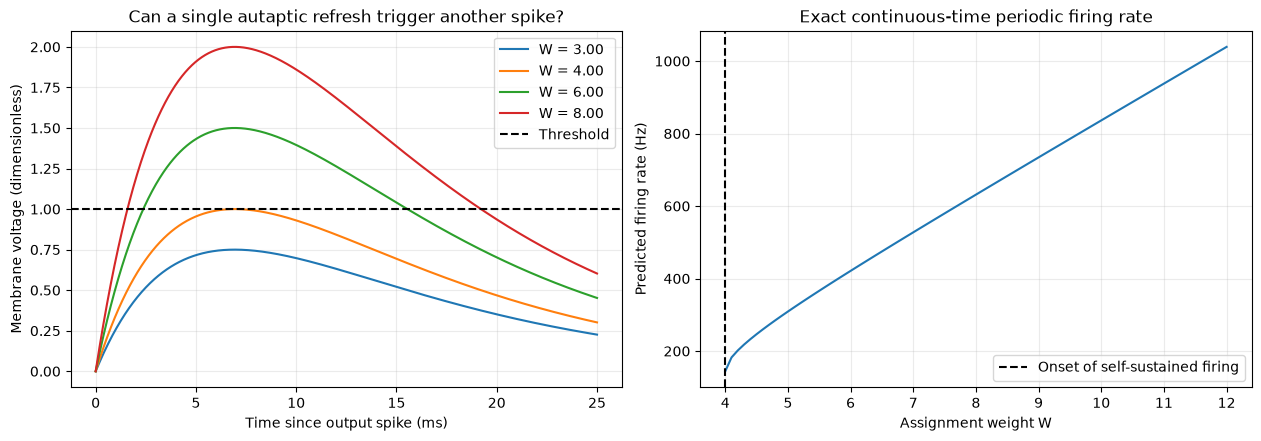

In [2]:
t_peak = np.log(tm/te) / (1/te - 1/tm)
peak_kernel = float(kernel(t_peak, te))
w_critical = vth / peak_kernel

def first_self_spike(weight):
    if weight * peak_kernel <= vth:
        return np.nan
    return brentq(lambda t: weight*kernel(t, te) - vth, 1e-10, t_peak)

weights = np.linspace(2.0, 12.0, 101)
isi = np.array([first_self_spike(w) for w in weights])
rates = 1000 / isi
print(f"Peak after a spike: {t_peak:.4f} ms; max kernel: {peak_kernel:.4f}")
print(f"Critical assignment weight: W_E > {w_critical:.4f} (strict threshold)")
print(f"For W_E={self_weight:g}: ISI={first_self_spike(self_weight):.4f} ms, "
      f"rate={1000/first_self_spike(self_weight):.1f} Hz")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), constrained_layout=True)
t = np.linspace(0, 25, 1200)
for w in (3.0, w_critical, 6.0, self_weight):
    axes[0].plot(t, w*kernel(t, te), label=f"W = {w:.2f}")
axes[0].axhline(vth, color="black", linestyle="--", label="Threshold")
axes[0].set(xlabel="Time since output spike (ms)", ylabel="Membrane voltage (dimensionless)",
            title="Can a single autaptic refresh trigger another spike?")
axes[0].legend()
axes[1].plot(weights, rates)
axes[1].axvline(w_critical, linestyle="--", color="black", label="Onset of self-sustained firing")
axes[1].set(xlabel="Assignment weight W", ylabel="Predicted firing rate (Hz)",
            title="Exact continuous-time periodic firing rate")
axes[1].legend()
for ax in axes: ax.grid(alpha=0.25)
plt.show()

## 3. When can inhibition *permanently* stop the autaptic loop?

Suppose an inhibitory pulse is delivered **immediately after an output spike**. At that moment $v=0$, $E=W_E$, and $I=J$; no further input is delivered. Then

$$\boxed{v(t)=W_EK_e(t)-JK_i(t).}$$

To prevent the *next* spike, we require

$$W_EK_e(t)-JK_i(t)<v_\mathrm{th}\qquad\text{for every }t>0.$$

Because $K_i(t)>0$ for $t>0$, this is equivalent to

$$\boxed{J>J_{\mathrm{crit}}=\max\left\{0,\sup_{t>0}\frac{W_EK_e(t)-v_\mathrm{th}}{K_i(t)}\right\}.}$$

This is an **exact criterion for this initial condition**; the supremum is computed numerically. Equality is a threshold-touching boundary. If the next spike never occurs, the assignment $E\leftarrow W_E$ is never refreshed and both currents decay to zero: the persistent state terminates.

**Crucial limitation:** Real inhibition typically arrives *between* output spikes. Then the state is $(v_0,E_0,I_0)\ne(0,W_E,J)$, and we must instead test

$$\sup_{t>0}\left[v_0e^{-t/\tau_m}+E_0K_e(t)-I_0K_i(t)\right]<v_\mathrm{th}.$$

A simple peak inhibition estimate based on the mean firing rate is insufficient to establish termination. A continuously spiking presynaptic competitor delivers a **train of inhibitory events**, rather than the one pulse studied here.

A pulse just after reset must exceed J = 2.8757 for W=8.


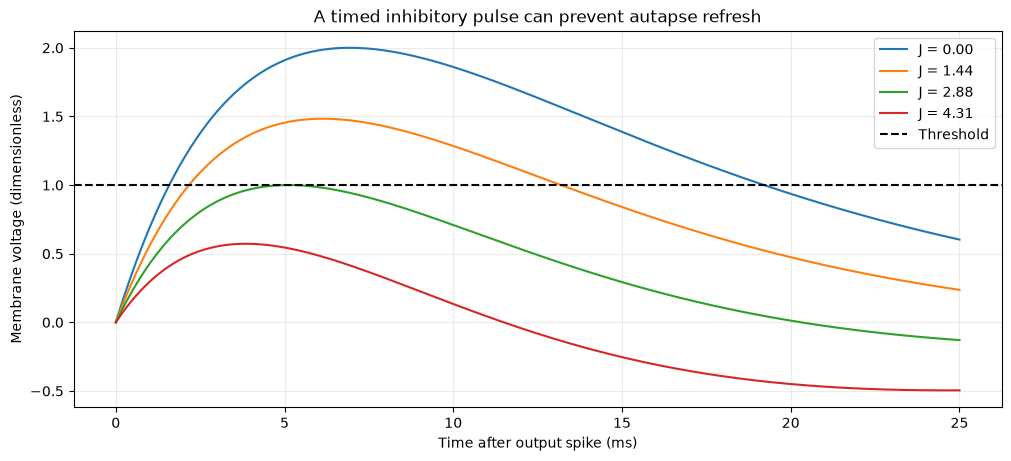

In [3]:
def peak_after_inhibition(weight, J):
    response = lambda t: weight*kernel(t, te) - J*kernel(t, ti)
    # The maximum could be at t=0, an internal maximum, or asymptotically zero.
    grid = np.linspace(0, 400, 4001)
    candidate = int(np.argmax(response(grid)))
    lo, hi = grid[max(0, candidate-1)], grid[min(len(grid)-1, candidate+1)]
    opt = minimize_scalar(lambda t: -response(t), bounds=(lo, hi), method="bounded")
    return max(0.0, float(-opt.fun))

# Direct minimax root for the phase-specific pulse amplitude.
Jcrit = brentq(lambda J: peak_after_inhibition(self_weight, J) - vth, 0, 100)
assert peak_after_inhibition(self_weight, Jcrit*1.001) < vth
assert peak_after_inhibition(self_weight, Jcrit*0.999) > vth
print(f"A pulse just after reset must exceed J = {Jcrit:.4f} for W={self_weight:g}.")

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for J in (0, 0.5*Jcrit, Jcrit, 1.5*Jcrit):
    ax.plot(t, voltage(t, E0=self_weight, I0=J), label=f"J = {J:.2f}")
ax.axhline(vth, color="black", linestyle="--", label="Threshold")
ax.set(xlabel="Time after output spike (ms)", ylabel="Membrane voltage (dimensionless)",
       title="A timed inhibitory pulse can prevent autapse refresh")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 4. From one neuron to two competing neurons

Now connect neurons $A$ (old) and $B$ (new) by **ordinary inhibitory synapses**. Their equations between events are

$$\tau_m\dot v_j=-v_j+X_j+E_j-I_j,\qquad
\tau_x\dot X_j=-X_j,\quad \tau_e\dot E_j=-E_j,\quad \tau_i\dot I_j=-I_j.$$

On a spike by $j$, set $v_j\leftarrow0$, $E_j\leftarrow W_E$, and inject inhibition into the other neuron: $I_k\leftarrow I_k+g$ for $k\ne j$. Camera spikes add $\beta$ to the corresponding external current.

This construction does **not** assume either representation wins. We test three matched protocols with the exact Notebook 15 stimulus timing: **old only** (2,4,6 ms), **new only** (35,37,39 ms), and **old then new** (both bursts). The neuronal parameters are identical across trials.

Replacement requires all three observable conditions in a sufficiently late window: (i) $A$ persists in the old-only control, (ii) $B$ persists in the new-only control, (iii) in the replacement trial $A$ is suppressed relative to its control **and** $B$ fires persistently.

The analytical single-neuron condition constrains $W_E$, but **cannot by itself prove** two-neuron switching. In particular, inhibitory pulses arrive at phases determined by spike timing; the first-crossing condition becomes a coupled event-driven problem. We therefore perform a small, reproducible numerical experiment rather than importing a mean-current assumption.

In [4]:
import brian2 as b2
from tqdm.auto import tqdm

b2.prefs.codegen.target = "numpy"

def two_neurons(protocol, inhibition, drive=camera_gain, dt_ms=0.05, record=False):
    b2.start_scope()
    b2.defaultclock.dt = dt_ms*b2.ms
    timings = []
    indices = []
    if protocol in ("old_only", "replacement"):
        timings += [2., 4., 6.]
        indices += [0, 0, 0]
    if protocol in ("new_only", "replacement"):
        timings += [35., 37., 39.]
        indices += [1, 1, 1]
    order = np.argsort(timings, kind="stable")
    camera = b2.SpikeGeneratorGroup(2, np.asarray(indices)[order],
                                   np.asarray(timings)[order]*b2.ms)
    params = dict(tm_model=tm*b2.ms, tx_model=tx*b2.ms,
                  te_model=te*b2.ms, ti_model=ti*b2.ms,
                  threshold_model=vth, weight_model=self_weight,
                  drive_model=drive, inhibition_model=inhibition)
    neurons = b2.NeuronGroup(2, """
        dv/dt = (-v + Iext + Iexc - Iinh)/tm_model : 1
        dIext/dt = -Iext/tx_model : 1
        dIexc/dt = -Iexc/te_model : 1
        dIinh/dt = -Iinh/ti_model : 1
        """, threshold="v > threshold_model", reset="v = 0",
        method="exact", namespace=params)
    neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = 0
    input_syn = b2.Synapses(camera, neurons, on_pre="Iext_post += drive_model",
                           namespace=params)
    input_syn.connect(j="i")
    self_syn = b2.Synapses(neurons, neurons, on_pre="Iexc_post = weight_model",
                          namespace=params)
    self_syn.connect(i=[0, 1], j=[0, 1])
    objects = [camera, neurons, input_syn, self_syn]
    if inhibition > 0:
        cross = b2.Synapses(neurons, neurons,
                           on_pre="Iinh_post += inhibition_model", namespace=params)
        cross.connect(i=[0, 1], j=[1, 0])
        objects.append(cross)
    spikes = b2.SpikeMonitor(neurons)
    objects.append(spikes)
    if record:
        state = b2.StateMonitor(neurons, ("v", "Iext", "Iexc", "Iinh"),
                                record=True, when="end")
        objects.append(state)
    b2.Network(*objects).run(110*b2.ms)
    result = dict(t=np.asarray(spikes.t/b2.ms), i=np.asarray(spikes.i, dtype=int))
    if record:
        result["time"] = np.asarray(state.t/b2.ms)
        result["state"] = {k: np.asarray(getattr(state, k)).copy()
                           for k in ("v", "Iext", "Iexc", "Iinh")}
        assert all(np.isfinite(x).all() for x in result["state"].values())
    return result

def spike_count(run, neuron, start, end):
    return int(np.count_nonzero((run["i"] == neuron) &
                                (run["t"] >= start) & (run["t"] < end)))

# Basic control: with no cross-inhibition, the old neuron's output must be
# unaffected by whether a later camera burst is directed to the other neuron.
zero_old = two_neurons("old_only", 0.0)
zero_replacement = two_neurons("replacement", 0.0)
assert np.array_equal(zero_old["t"][zero_old["i"] == 0],
                      zero_replacement["t"][zero_replacement["i"] == 0])
print("PASS: no-interaction control preserves the old neuron's spike train")

WARNING    /home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
 [py.warnings]


PASS: no-interaction control preserves the old neuron's spike train


## 5. Map recruitment and suppression without presuming a successful outcome

We vary the **camera event jump** $\beta$ and the **cross-inhibition weight** $g$. This is a small diagnostic grid, not a parameter optimization. The no-replacement and new-only controls run at the same $g$ and $\beta$ as the replacement trials.

To avoid classifying one transient spike as persistence, we require **at least two output spikes in each of two nonoverlapping late intervals**, [70,85) and [85,100) ms. The intervals begin 31 ms after the last new sensory event. At $W_E=8$, the isolated continuous-time period derived above is expected to be much shorter than either interval.

A configuration counts as a replacement candidate only if the old-only control persists, the new-only control persists, the old neuron is absent late in the replacement run, and the new neuron persists late in the replacement run. We also display **suppression relative to the control**, avoiding the trivial claim that an old neuron was replaced if it had already stopped firing.

These are deliberately stringent binary criteria for this two-neuron system; they are not equivalent to preservation of all pixels in a five-pixel edge.

Sensory-drive levels: 100%|██████████| 5/5 [00:25<00:00,  5.02s/it]


,drive,inhibition,old_control_persists,new_control_persists,new_replacement_persists,old_removed,candidate,old_control_70_85,old_control_85_100,new_control_70_85,new_control_85_100,old_replacement_70_85,old_replacement_85_100,new_replacement_70_85,new_replacement_85_100
0,6.0,0.0,True,True,True,False,False,9,10,10,9,9,10,10,9
1,6.0,0.5,True,True,False,False,False,9,10,10,9,9,10,0,0
2,6.0,1.0,True,True,False,False,False,9,10,10,9,9,10,0,0
3,6.0,2.0,True,True,False,False,False,9,10,10,9,9,10,0,0
4,6.0,4.0,True,True,False,False,False,9,10,10,9,9,10,0,0
5,6.0,6.0,True,True,False,False,False,9,10,10,9,9,10,0,0
6,6.0,8.0,True,True,False,False,False,9,10,10,9,9,10,0,0
7,10.0,0.0,True,True,True,False,False,10,9,9,9,10,9,9,9
8,10.0,0.5,True,True,False,False,False,10,9,9,9,9,9,0,0
9,10.0,1.0,True,True,False,False,False,10,9,9,9,10,9,0,0


Candidate configurations: 3 / 35


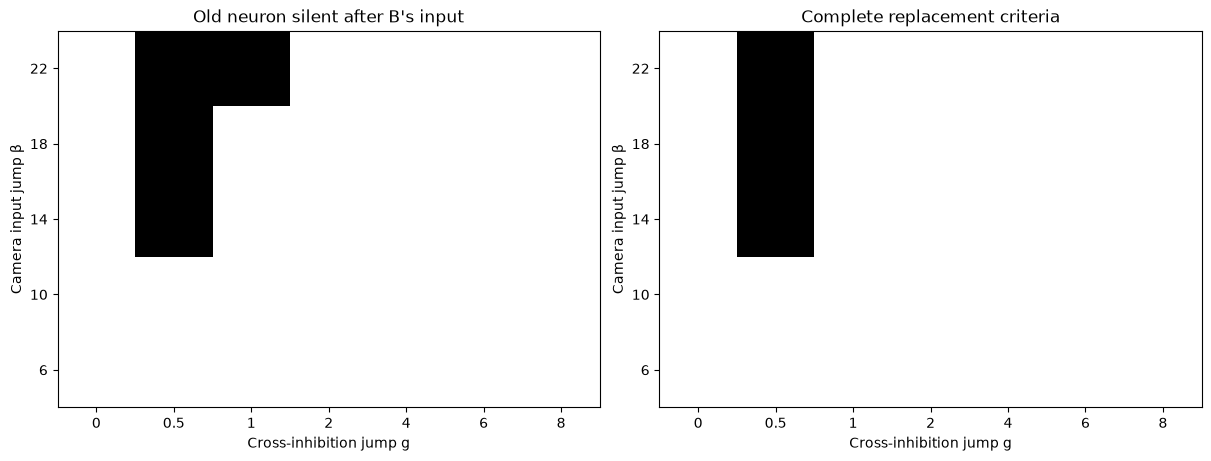

In [5]:
drive_values = (6., 10., 14., 18., 22.)
inhibition_values = (0., 0.5, 1., 2., 4., 6., 8.)
records = []
for drive in tqdm(drive_values, desc="Sensory-drive levels"):
    for g in inhibition_values:
        old = two_neurons("old_only", g, drive=drive)
        new = two_neurons("new_only", g, drive=drive)
        replacement = two_neurons("replacement", g, drive=drive)
        counts = {}
        for label, run, neuron in (("old_control", old, 0),
                                   ("new_control", new, 1),
                                   ("old_replacement", replacement, 0),
                                   ("new_replacement", replacement, 1)):
            counts[label + "_70_85"] = spike_count(run, neuron, 70, 85)
            counts[label + "_85_100"] = spike_count(run, neuron, 85, 100)
        old_persist = min(counts["old_control_70_85"], counts["old_control_85_100"]) >= 2
        new_persist = min(counts["new_control_70_85"], counts["new_control_85_100"]) >= 2
        replacement_persist = min(counts["new_replacement_70_85"],
                                  counts["new_replacement_85_100"]) >= 2
        old_removed = counts["old_replacement_70_85"] == counts["old_replacement_85_100"] == 0
        records.append(dict(drive=drive, inhibition=g, old_control_persists=old_persist,
                            new_control_persists=new_persist,
                            new_replacement_persists=replacement_persist,
                            old_removed=old_removed,
                            candidate=old_persist and new_persist and replacement_persist and old_removed,
                            **counts))
summary = pd.DataFrame(records)
display(summary)
print(f"Candidate configurations: {int(summary.candidate.sum())} / {len(summary)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, column, title in zip(axes, ("old_removed", "candidate"),
                             ("Old neuron silent after B's input", "Complete replacement criteria")):
    grid = summary.pivot(index="drive", columns="inhibition", values=column)
    ax.imshow(grid.to_numpy(dtype=float), origin="lower", aspect="auto", vmin=0, vmax=1,
              cmap="Greys")
    ax.set_xticks(range(len(grid.columns)), labels=[f"{x:g}" for x in grid.columns])
    ax.set_yticks(range(len(grid.index)), labels=[f"{x:g}" for x in grid.index])
    ax.set(xlabel="Cross-inhibition jump g", ylabel="Camera input jump β", title=title)
plt.show()

## 6. Inspect time dependence and check numerical robustness

The parameter grid alone does not establish how a switch occurs. Select a configuration meeting the complete replacement criteria if one exists; otherwise choose the one maximizing the new neuron's late spiking while minimizing the old neuron's late spiking, *provided the old-only control persists*. Show both spike rasters and the old/new synaptic currents.

Then repeat the selected configuration at $\Delta t=0.1$, 0.05 and 0.025 ms. We compare late spike counts and first/last spikes, not necessarily exact spike times. A finite grid cannot prove global stability, and exact event timings can differ when threshold crossings are sampled on a clock.

**Avoid a false success:** if the new neuron fires in the replacement run but the old-only control has no late activity, there has been no competitive replacement.

Diagnostic selection (not a fitted optimum): {'drive': 14.0, 'inhibition': 0.5, 'candidate': True}


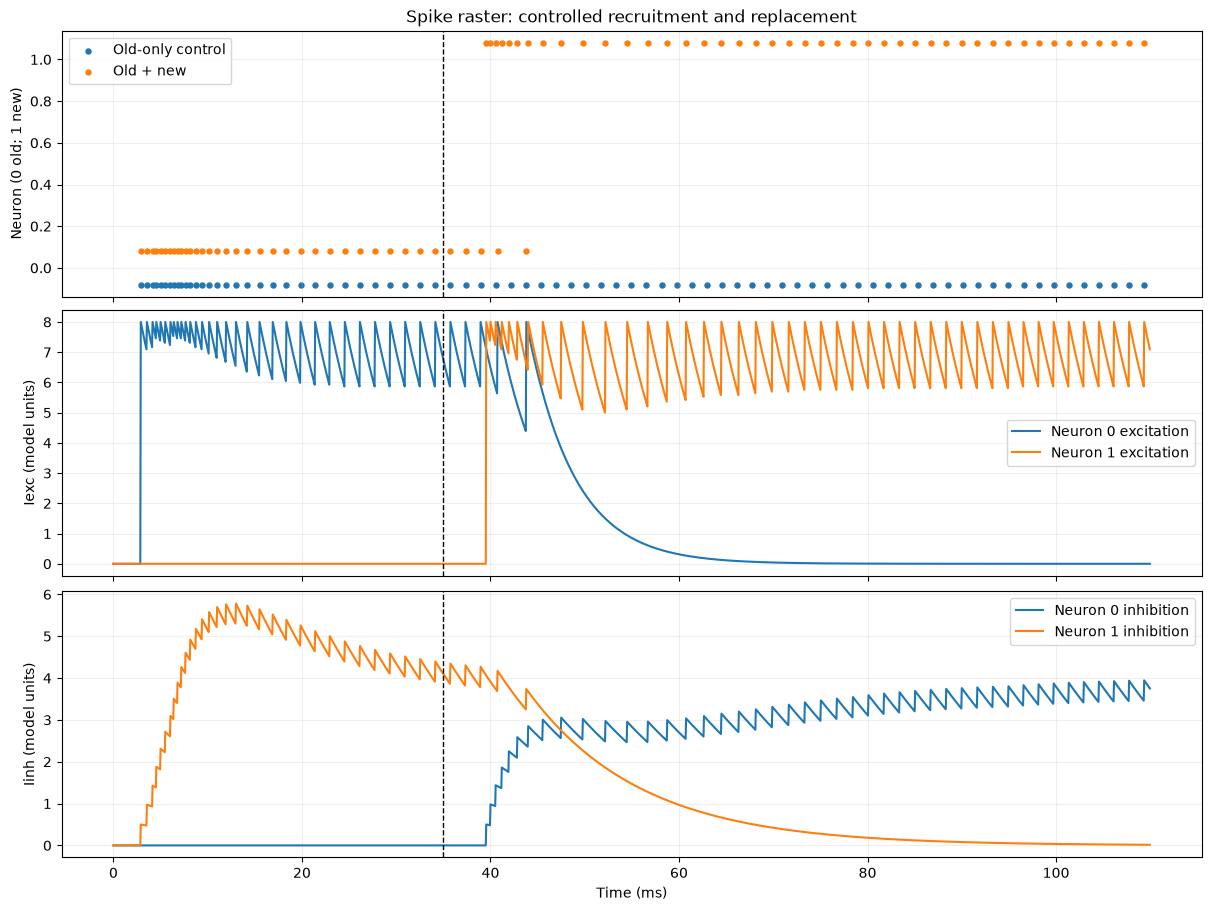

,dt_ms,old_70_85,old_85_100,new_70_85,new_85_100
0,0.100,0,0,9,9
1,0.050,0,0,8,10
2,0.025,0,0,9,9


In [6]:
eligible = summary[summary.old_control_persists & summary.new_control_persists]
if len(eligible):
    ranked = eligible.sort_values(["candidate", "new_replacement_85_100",
                                   "old_replacement_85_100"],
                                  ascending=[False, False, True])
    chosen = ranked.iloc[0]
    print("Diagnostic selection (not a fitted optimum):", chosen[["drive", "inhibition", "candidate"]].to_dict())
    old_run = two_neurons("old_only", chosen.inhibition, chosen.drive, record=True)
    both_run = two_neurons("replacement", chosen.inhibition, chosen.drive, record=True)
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, constrained_layout=True)
    for run, label, color in ((old_run, "Old-only control", "tab:blue"),
                              (both_run, "Old + new", "tab:orange")):
        axes[0].scatter(run["t"], run["i"] + (0.08 if label == "Old + new" else -0.08),
                        s=13, label=label, color=color)
    axes[0].set(ylabel="Neuron (0 old; 1 new)", title="Spike raster: controlled recruitment and replacement")
    axes[0].legend()
    for idx in (0, 1):
        axes[1].plot(both_run["time"], both_run["state"]["Iexc"][idx], label=f"Neuron {idx} excitation")
        axes[2].plot(both_run["time"], both_run["state"]["Iinh"][idx], label=f"Neuron {idx} inhibition")
    axes[1].set_ylabel("Iexc (model units)")
    axes[2].set_ylabel("Iinh (model units)")
    for ax in axes:
        ax.axvline(35, color="black", linestyle="--", linewidth=1)
        ax.legend()
        ax.grid(alpha=0.2)
    axes[-1].set_xlabel("Time (ms)")
    plt.show()
    checks = []
    for dt in (0.1, 0.05, 0.025):
        run = two_neurons("replacement", float(chosen.inhibition),
                          float(chosen.drive), dt_ms=dt)
        checks.append(dict(dt_ms=dt,
            old_70_85=spike_count(run, 0, 70, 85), old_85_100=spike_count(run, 0, 85, 100),
            new_70_85=spike_count(run, 1, 70, 85), new_85_100=spike_count(run, 1, 85, 100)))
    display(pd.DataFrame(checks))
else:
    print("No configuration sustains *both* isolated controls. Do not claim competitive replacement.")

## 7. What is established, and what remains to derive?

### Structural results (derived mathematically)

- The exact between-event voltage is a sum of exponential response kernels.
- For an isolated assignment autapse without inhibition or refractory, the condition $W_E\max K_e>v_{th}$ is sufficient to generate an indefinitely repeating interspike interval, because the same post-spike state repeats.
- A sufficiently strong inhibitory pulse can terminate that loop by preventing *its next* threshold crossing. The required pulse is **phase dependent**.

### Finite tests (numerical evidence only)

- The kernel formula is checked against an independent matrix exponential.
- The phase-specific inhibitory boundary is evaluated and bracketed numerically.
- A two-neuron Brian2 network tests recruitment, suppression, and persistence with matched controls and timestep refinement.

### Important limitations

- A two-neuron direct-inhibition circuit is not equivalent to Notebook 15's five-pixel edge or its inhibitory-interneuron variants.
- The cross-inhibition event is modeled as a fixed current jump; this is a mathematical abstraction of lateral inhibition, not a claim of a specific inhibitory neurotransmitter or synaptic physiology.
- Simultaneous spiking and refractory effects, stochastic camera events, synaptic depression and adaptation are excluded from the first derivation. They should be added **only when a failure mechanism is identified**.
- The exact single-pulse criterion assumes inhibition arrives at the specified post-spike phase. The coupled competition requires solving a hybrid dynamical system, so static mean-current estimates cannot provide exact switching thresholds.

**Next experiment:** If the two-neuron circuit has no viable switching regime, analyze the measured voltage/current states at B's first failed recruitment opportunity. Use the precise state-dependent threshold-crossing criterion to decide whether sensory drive, adaptation, or depression addresses the actual bottleneck; do not simply expand the parameter sweep.